# Construindo o TARGET no dataset de aprovação de cartão de crédito

Este notebook nasce de uma pergunta que aparece com frequência entre alunos do Tech Challenge Fase 2: se eu mudo o critério de atraso usado para definir quem é "bom pagador" e quem é "mau pagador", a proporção entre as duas classes muda drasticamente — às vezes de algo próximo de 90/10 para algo ainda mais extremo, como 98/2, dependendo de quão rígido é o critério. Diante disso, surge a tentação de escolher o critério que produz a proporção mais "confortável" para modelagem, evitando desbalanceamento.

O objetivo aqui é mostrar, com o dataset real `rikdifos/credit-card-approval-prediction` (o mesmo usado no desafio), por que esse raciocínio está invertido. A variável TARGET representa um conceito de negócio — o que, de fato, caracteriza um cliente inadimplente — e não um artefato estatístico a ser ajustado até que o dataset "fique bonito". A proporção resultante é uma consequência da definição de negócio escolhida, nunca o critério de escolha em si.

Para isso, vamos construir o TARGET usando dois critérios de atraso diferentes, comparar as proporções resultantes lado a lado, e discutir por que a decisão entre eles deve ser justificada pelo significado de cada código de status, não pelo equilíbrio de classes que cada um produz.

## Onde colocar os dados

Este notebook é standalone e assume a mesma convenção de pastas do template `drlima/postech-tech-challenge-fase2-template`: ele roda a partir de uma pasta `notebooks/`, com os dados brutos em `../data/raw/`. Ou seja, a estrutura esperada a partir da raiz do projeto é:

```
projeto/
├── data/
│   └── raw/
│       ├── application_record.csv
│       └── credit_record.csv
└── notebooks/
    └── demo_criacao_target.ipynb
```

Os arquivos `application_record.csv` e `credit_record.csv` vêm do dataset [rikdifos/credit-card-approval-prediction](https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction) no Kaggle. Se você for executar este notebook fora dessa estrutura de pastas, baixe os dois arquivos e ajuste a variável `DATA_DIR` na célula de configuração logo abaixo para apontar para o diretório onde eles estiverem.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
# Este notebook não tem nenhuma etapa aleatória (não há split, amostragem ou
# treino de modelo) — RANDOM_STATE é fixado aqui só por convenção, para ficar
# consistente com os notebooks de modelagem do template, que de fato dependem
# de reprodutibilidade.

# Ajuste este caminho caso os CSVs estejam em outro local.
DATA_DIR = Path("../data/raw")

APPLICATION_PATH = DATA_DIR / "application_record.csv"
CREDIT_PATH = DATA_DIR / "credit_record.csv"

for path in (APPLICATION_PATH, CREDIT_PATH):
    if not path.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado em {path.resolve()}. "
            "Ajuste DATA_DIR para o diretório correto dos CSVs."
        )

print("Diretório de dados:", DATA_DIR.resolve())

Diretório de dados: /home/drl/fiap/dtat/2dtat-bb/data/raw


In [2]:
credit_record = pd.read_csv(CREDIT_PATH)

print("Shape:", credit_record.shape)
print("Clientes únicos (ID):", credit_record["ID"].nunique())
credit_record.head()

Shape: (1048575, 3)
Clientes únicos (ID): 45985


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [3]:
# Verificação rápida de sanidade antes de prosseguir: sem isso, qualquer análise
# de STATUS corre o risco de estar sobre dados incompletos ou corrompidos.
assert credit_record["ID"].notna().all(), "há valores nulos em ID"
assert credit_record["STATUS"].notna().all(), "há valores nulos em STATUS"
assert credit_record["STATUS"].value_counts().sum() == len(credit_record)

print("Sanidade OK: sem nulos em ID/STATUS, e a soma das contagens de STATUS bate com o total de linhas.")

Sanidade OK: sem nulos em ID/STATUS, e a soma das contagens de STATUS bate com o total de linhas.


## O que significam `MONTHS_BALANCE` e cada código de `STATUS`

O `credit_record.csv` registra, para cada cliente (`ID`), um histórico mensal de pagamento. A coluna `MONTHS_BALANCE` indica a distância em meses até o mês de referência dos dados: `0` é o mês mais recente disponível, e valores negativos (`-1`, `-2`, ...) são meses anteriores. Neste notebook, o critério de TARGET usado é do tipo *"aconteceu alguma vez"* — não importa em qual mês o atraso ocorreu, só se ocorreu. Essa é, em si, uma escolha (poderíamos, por exemplo, considerar só os últimos 12 meses) que vamos retomar mais adiante, depois de calcularmos o TARGET.

A coluna `STATUS`, por sua vez, registra a situação de pagamento naquele mês. Antes de decidir qualquer critério de TARGET, é indispensável entender o que cada código representa — essa é a informação de negócio que vai guiar a decisão, não o inverso. Os limiares abaixo seguem a convenção de mercado de "dias em atraso" (*days past due*, DPD), documentada na página do dataset no Kaggle ([rikdifos/credit-card-approval-prediction](https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction)):

| Código | Significado |
|---|---|
| `0` | Atraso de 1 a 29 dias |
| `1` | Atraso de 30 a 59 dias |
| `2` | Atraso de 60 a 89 dias |
| `3` | Atraso de 90 a 119 dias |
| `4` | Atraso de 120 a 149 dias |
| `5` | Atraso superior a 150 dias, tratado como prejuízo (dívida incobrável) |
| `C` | Em dia — fatura paga naquele mês (sem saldo devedor) |
| `X` | Sem empréstimo ativo naquele mês |

Note que os códigos numéricos formam uma escala crescente de gravidade: `0` é um atraso leve, recém-iniciado, enquanto `5` já representa perda financeira reconhecida pela instituição. `C` e `X` não indicam inadimplência — indicam, respectivamente, que a fatura daquele mês foi paga em dia (não que o contrato foi encerrado) e ausência de crédito ativo no mês.

In [4]:
status_counts = credit_record["STATUS"].value_counts()
status_share = credit_record["STATUS"].value_counts(normalize=True).round(4)

pd.DataFrame({"contagem": status_counts, "proporção": status_share})

,contagem,proporção
STATUS,,
C,442031,0.4216
0,383120,0.3654
X,209230,0.1995
1,11090,0.0106
5,1693,0.0016
2,868,0.0008
3,320,0.0003
4,223,0.0002


Antes de seguir, vale uma distinção importante: a tabela acima mostra a proporção de **registros mensais** (uma linha = um cliente em um mês) em cada status — não a proporção de **clientes** que serão classificados como bom ou mau pagador. Um cliente que teve um único mês com status `1` em 36 meses de histórico conta como "1 mês em atraso" na tabela acima, mas conta como "1 cliente mau pagador inteiro" depois da consolidação por `ID`, que faremos a seguir. As duas proporções não são a mesma coisa — a proporção bom/mau pagador só aparece de fato depois que consolidamos o histórico de cada cliente em uma única flag, nas próximas seções.

> **Pare e pense.** Ao observar a tabela acima, é natural notar que atrasos graves (`2` a `5`) são bem mais raros que atrasos leves (`0` e `1`). Isso pode gerar a tentação de escolher o critério de TARGET que produza uma proporção de classes mais equilibrada, evitando o trabalho extra de lidar com desbalanceamento na modelagem.
>
> Essa lógica está invertida. O critério que define "mau pagador" é uma decisão de **negócio**: ele precisa refletir o que a instituição financeira efetivamente entende como inadimplência relevante para negar ou aprovar crédito. A proporção de bons e maus pagadores que resulta dessa escolha é uma **consequência**, não um critério de seleção. Escolher o critério pela proporção que ele produz é inverter a causalidade — e corre o risco de definir um TARGET que não corresponde a nenhum conceito real de risco de crédito.
>
> O caminho correto é: primeiro decidir, com base em significado de negócio, o que caracteriza inadimplência; depois observar a proporção resultante; e, se houver desbalanceamento, tratá-lo nas etapas de modelagem — não redefinir o TARGET para "consertar" a proporção.

## Critério 1 — permissivo (atraso a partir de 30 dias)

O primeiro critério classifica como mau pagador qualquer cliente que tenha registrado, em pelo menos um mês, um status de atraso — de leve (`1`, 30-59 dias) a prejuízo (`5`, mais de 150 dias). A justificativa de negócio aqui é conservadora do ponto de vista do risco: qualquer sinal de atraso, mesmo que pequeno, é tratado como evidência suficiente de comportamento de pagamento problemático, já que atrasos leves recorrentes tendem a preceder atrasos mais graves.

Note que o código `0` (1 a 29 dias) é deliberadamente **excluído** — um atraso de poucos dias é comum mesmo entre bons pagadores (esquecimento pontual, data de vencimento desalinhada com o recebimento de salário, etc.) e não costuma ser, isoladamente, um indicador de inadimplência.

In [5]:
# STATUS é uma coluna de texto (dtype object), não numérica — por isso comparamos
# com strings ("1", "2", ...). Usar isin([1, 2, 3]) com inteiros não geraria erro,
# geraria silenciosamente uma flag toda zero.
credit_record["bad_permissivo"] = credit_record["STATUS"].isin(["1", "2", "3", "4", "5"]).astype(int)

# Consolida por cliente: se em QUALQUER mês o cliente teve atraso, ele é marcado
# como mau pagador ("ever bad"). Essa também é uma escolha de critério — não a
# única defensável — e vamos discutir uma implicação dela logo abaixo.
target_permissivo = (
    credit_record.groupby("ID")["bad_permissivo"]
    .max()
    .reset_index()
    .rename(columns={"bad_permissivo": "TARGET"})
)

target_permissivo["TARGET"].value_counts(normalize=True)

TARGET
0    0.883658
1    0.116342
Name: proportion, dtype: float64

### Um viés escondido na agregação "ever" por cliente

A consolidação acima usa `.max()` sobre a flag binária: se o cliente teve atraso em **qualquer** mês do histórico, ele é marcado como mau pagador. Essa escolha parece neutra, mas não é — ela mistura dois efeitos diferentes: o comportamento de pagamento do cliente e o **tempo de exposição** (quantos meses de histórico ele tem em `credit_record`). Quanto mais meses um cliente é observado, maior a chance de que, em algum desses meses, um atraso apareça — mesmo que o risco real do cliente não seja maior que o de um cliente com histórico curto. Isso é um viés estatístico puro de exposição, não um sinal de risco de negócio, e é exatamente o tipo de efeito que este notebook está tentando ensinar a não deixar "vazar" para dentro da definição do TARGET pela porta dos fundos.

Vamos confirmar isso nos dados: agrupamos os clientes por quantidade de meses de histórico (usando `MONTHS_BALANCE`) e comparamos a taxa de "mau pagador" (critério permissivo) em cada faixa.

In [6]:
meses_historico = (
    credit_record.groupby("ID")["MONTHS_BALANCE"]
    .count()
    .rename("meses_historico")
    .reset_index()
)

exposicao = target_permissivo.merge(meses_historico, on="ID")
exposicao["faixa_meses_historico"] = pd.cut(
    exposicao["meses_historico"], bins=[0, 5, 10, 20, 30, 40, 50, 100]
)

exposicao.groupby("faixa_meses_historico", observed=True)["TARGET"].mean().rename(
    "taxa_mau_pagador"
).to_frame().round(4)

,taxa_mau_pagador
faixa_meses_historico,
"(0, 5]",0.0336
"(5, 10]",0.0846
"(10, 20]",0.1255
"(20, 30]",0.1277
"(30, 40]",0.1379
"(40, 50]",0.1598
"(50, 100]",0.1599


A taxa de mau pagador sobe de forma consistente conforme o histórico fica mais longo — não porque o cliente piorou, mas porque um cliente observado por mais tempo tem mais chances de que "alguma vez" apareça um atraso. Na prática de risco de crédito, esse problema costuma ser tratado com janelas de performance fixas (por exemplo, "atraso de 60+ dias nos primeiros 12 meses de relacionamento") ou com análise de vintage, em vez de um "ever" sobre históricos de tamanhos desiguais. Este demo mantém o `.max()` simples por ser didático, e porque não altera a conclusão central sobre a escolha do critério de STATUS — mas fica registrado: a agregação por cliente também é uma decisão de negócio, e também merece a mesma desconfiança que aplicamos ao limiar de dias de atraso.

## Critério 2 — rígido (atraso grave ou persistente)

O segundo critério eleva a régua: só é classificado como mau pagador o cliente que tenha registrado, em pelo menos um mês, um atraso de 60 dias ou mais (`2` a `5`). A justificativa de negócio muda: aqui, o interesse é isolar inadimplência grave ou persistente, desconsiderando atrasos leves e moderados (`0` e `1`) como ruído aceitável dentro da operação normal de crédito.

Esse é um critério igualmente legítimo do ponto de vista de negócio, mas vale uma ressalva de vocabulário: a convenção regulatória (Basileia) reserva o termo "default" para atraso de 90 dias ou mais. O critério rígido usado aqui (60+ dias) é mais conservador que isso — sinaliza risco grave antes de o default regulatório se consolidar — e o critério permissivo (30+ dias) está bem abaixo dessa convenção. Tratamos os dois, neste notebook, como aproximações didáticas de "mau pagador", não como sinônimos diretos de "default". A diferença entre os dois critérios não é estatística: é uma escolha diferente sobre qual comportamento de pagamento a instituição considera inaceitável.

In [7]:
# Mesmo pipeline da célula anterior — a única diferença é o limiar de STATUS
# passado a isin() (aqui, 60+ dias em vez de 30+ dias).
credit_record["bad_rigido"] = credit_record["STATUS"].isin(["2", "3", "4", "5"]).astype(int)

target_rigido = (
    credit_record.groupby("ID")["bad_rigido"]
    .max()
    .reset_index()
    .rename(columns={"bad_rigido": "TARGET"})
)

target_rigido["TARGET"].value_counts(normalize=True)

TARGET
0    0.985495
1    0.014505
Name: proportion, dtype: float64

## Consolidando com `application_record.csv`

Com o TARGET calculado por cliente para os dois critérios, fazemos o merge (`inner`) com `application_record.csv` — apenas clientes presentes em ambos os arquivos entram na base final. Usamos `inner join` porque um cliente sem histórico de crédito (`credit_record`) não tem como ter um TARGET definido, e um cliente sem dados cadastrais (`application_record`) não tem como ter atributos preditores.

Essa escolha, no entanto, tem uma implicação de negócio que precisa ficar explícita: `credit_record.csv` só contém clientes que **já tiveram um cartão de crédito emitido** — ou seja, clientes que já foram aprovados no passado. Ao restringir a base a esse subconjunto, o TARGET nunca é observado para quem foi recusado. Isso é conhecido em risco de crédito como **viés de seleção / reject inference**: um modelo treinado só sobre aprovados pode não generalizar bem para decidir sobre novos candidatos, que incluem gente que seria recusada. É uma limitação real deste dataset (não deste notebook especificamente), e vamos quantificar o tamanho do descarte a seguir.

In [8]:
application_record_raw = pd.read_csv(APPLICATION_PATH)

ids_duplicados = application_record_raw[application_record_raw.duplicated("ID", keep=False)]
n_ids_duplicados = ids_duplicados["ID"].nunique()

print("Linhas totais:", len(application_record_raw))
print("IDs únicos:", application_record_raw["ID"].nunique())
print("IDs que aparecem mais de uma vez:", n_ids_duplicados)

ids_duplicados.sort_values("ID").head(4)

Linhas totais: 438557
IDs únicos: 438510
IDs que aparecem mais de uma vez: 47


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
425023,7022197,F,N,Y,0,450000.0,Commercial associate,Higher education,Separated,House / apartment,-19813,-1799,1,0,0,1,NaN,1.0
426818,7022197,M,Y,Y,3,135000.0,Working,Secondary / secondary special,Married,House / apartment,-11945,-735,1,0,0,1,Laborers,5.0
431911,7022327,M,Y,Y,0,256500.0,Commercial associate,Higher education,Married,House / apartment,-21503,-1674,1,0,0,1,Core staff,2.0
431545,7022327,F,N,Y,0,135000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-14771,-5298,1,0,0,0,High skill tech staff,1.0


Os IDs colidentes acima correspondem a registros de **pessoas diferentes** compartilhando o mesmo ID (repare que gênero, ocupação e/ou composição familiar mudam entre as linhas com o mesmo ID) — não são linhas repetidas, e sim uma peculiaridade conhecida deste dataset, provavelmente originada de reaproveitamento ou erro na geração do identificador. Ao consolidar, mantemos explicitamente a primeira ocorrência de cada ID (`keep="first"`). Neste snapshot dos dados isso não altera o resultado final, porque nenhum dos IDs colidentes aparece em `credit_record.csv` — mas isso é uma coincidência dos dados, não uma garantia do código, e por isso vale deixar registrado em vez de tratar como um passo de limpeza óbvio.

In [9]:
application_record = application_record_raw.drop_duplicates(subset="ID", keep="first")

base_permissivo = application_record.merge(target_permissivo, on="ID", how="inner")
base_rigido = application_record.merge(target_rigido, on="ID", how="inner")

# Quantificando o descarte do inner join (ver discussão acima sobre viés de seleção).
n_aplicantes = application_record["ID"].nunique()
n_com_historico = credit_record["ID"].nunique()
n_base_final = len(base_permissivo)

print(f"Aplicantes únicos (application_record):            {n_aplicantes:,}")
print(f"Clientes com histórico (credit_record):            {n_com_historico:,}")
print(f"Clientes na base final (após o inner join):        {n_base_final:,}")
print(f"Aplicantes descartados (sem histórico de crédito): {1 - n_base_final / n_aplicantes:.1%}")
print(f"Clientes com histórico descartados (sem cadastro): {1 - n_base_final / n_com_historico:.1%}")
print()

proporcoes_antes = pd.DataFrame({
    "permissivo (atraso >= 30 dias)": target_permissivo["TARGET"].value_counts(normalize=True),
    "rígido (atraso >= 60 dias)": target_rigido["TARGET"].value_counts(normalize=True),
}).rename(index={0: "bom pagador (0)", 1: "mau pagador (1)"})

proporcoes = pd.DataFrame({
    "permissivo (atraso >= 30 dias)": base_permissivo["TARGET"].value_counts(normalize=True),
    "rígido (atraso >= 60 dias)": base_rigido["TARGET"].value_counts(normalize=True),
}).rename(index={0: "bom pagador (0)", 1: "mau pagador (1)"})

print("Proporção de TARGET ANTES do merge (todos os clientes com histórico):")
display(proporcoes_antes.round(4))
print()
print("Proporção de TARGET DEPOIS do merge (só clientes com cadastro também):")
display(proporcoes.round(4))

Aplicantes únicos (application_record):            438,510
Clientes com histórico (credit_record):            45,985
Clientes na base final (após o inner join):        36,457
Aplicantes descartados (sem histórico de crédito): 91.7%
Clientes com histórico descartados (sem cadastro): 20.7%

Proporção de TARGET ANTES do merge (todos os clientes com histórico):


,permissivo (atraso >= 30 dias),rígido (atraso >= 60 dias)
TARGET,,
bom pagador (0),0.8837,0.9855
mau pagador (1),0.1163,0.0145



Proporção de TARGET DEPOIS do merge (só clientes com cadastro também):


,permissivo (atraso >= 30 dias),rígido (atraso >= 60 dias)
TARGET,,
bom pagador (0),0.8823,0.9831
mau pagador (1),0.1177,0.0169


Note dois pontos. Primeiro, `TARGET = 1` é a classe "mau pagador" (não "bom", como a intuição às vezes sugere) — vale sempre conferir a convenção ao trabalhar com uma variável binária de risco. Segundo, e mais importante: a proporção de mau pagador **muda** entre antes e depois do merge — no critério rígido, por exemplo, ela sobe de forma perceptível. Isso é evidência de que o subconjunto de clientes que sobrevive ao inner join não é neutro em relação ao TARGET: quem tem cadastro em `application_record` não é uma amostra aleatória de quem tem histórico de crédito. É outra manifestação do viés de seleção discutido acima, reforçando que o inner join, assim como o critério de STATUS, é uma decisão com efeito real sobre o TARGET — não um detalhe técnico neutro.

### Outra duplicata, mais silenciosa: o mesmo cadastro sob IDs diferentes

A colisão de IDs tratada acima é o caso fácil — são 47 casos, visíveis, e o `drop_duplicates` resolve. Há um segundo tipo de repetição que não aparece em nenhuma verificação por `ID` e que muda muito mais coisas: clientes com **IDs diferentes e cadastro idêntico em todas as colunas** — mesma renda ao centavo, mesma data de nascimento em dias, mesmo tempo de emprego em dias, mesmas categorias. Dificilmente são pessoas distintas; o mais provável é a mesma pessoa registrada várias vezes (múltiplos cartões, reprocessamentos, ou a forma como a base foi montada). Vamos medir quantos são, na base já consolidada com o critério rígido.

In [10]:
colunas_cadastro = [c for c in application_record.columns if c != "ID"]
perfil = pd.util.hash_pandas_object(base_rigido[colunas_cadastro].astype(str), index=False)
tamanho_do_perfil = perfil.groupby(perfil).transform("size")

print("Clientes na base consolidada:        ", len(base_rigido))
print("Perfis de cadastro distintos:        ", perfil.nunique())
print("Clientes com ao menos um 'gêmeo':    ", int((tamanho_do_perfil > 1).sum()), f"({(tamanho_do_perfil > 1).mean():.1%})")

por_perfil = base_rigido.groupby(perfil.values)["TARGET"].agg(["size", "sum"])
conflitantes = por_perfil[(por_perfil["sum"] > 0) & (por_perfil["sum"] < por_perfil["size"])]
print("Perfis com TARGET diferente entre gêmeos:", len(conflitantes),
      f"— contendo {int(conflitantes['sum'].sum())} dos {int(base_rigido['TARGET'].sum())} maus pagadores "
      f"({conflitantes['sum'].sum() / base_rigido['TARGET'].sum():.0%})")

Clientes na base consolidada:         36457
Perfis de cadastro distintos:         9728
Clientes com ao menos um 'gêmeo':     33320 (91.4%)
Perfis com TARGET diferente entre gêmeos: 269 — contendo 419 dos 616 maus pagadores (68%)


Nove em cada dez clientes têm um gêmeo de cadastro, e dois terços dos maus pagadores têm um gêmeo que é bom pagador. Para a construção do TARGET, que é o assunto deste notebook, isso não muda nada: o TARGET é definido por conta, a partir do histórico de pagamento de cada `ID`, e continua correto. Mas fica aqui o registro porque isso muda tudo na etapa seguinte. Um modelo treinado sobre o cadastro não tem como distinguir dois clientes com atributos idênticos — o que impõe um teto ao que qualquer modelo consegue fazer com esses dados — e um split treino/teste aleatório deixaria gêmeos dos dois lados, fazendo o modelo parecer prever o que na verdade está apenas memorizando. Os notebooks seguintes (`demo_modelagem_desbalanceada.ipynb` e `demo_tecnicas_avancadas.ipynb`) mostram o tamanho desse efeito e como avaliar de forma honesta, com divisões por grupo de perfil.

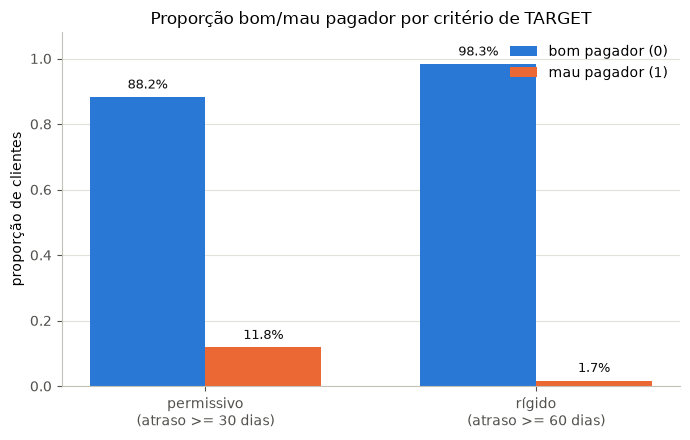

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))

criterios = ["permissivo\n(atraso >= 30 dias)", "rígido\n(atraso >= 60 dias)"]
bom_pagador = [proporcoes.loc["bom pagador (0)", c] for c in proporcoes.columns]
mau_pagador = [proporcoes.loc["mau pagador (1)", c] for c in proporcoes.columns]

x = np.arange(len(criterios))
largura = 0.35

cor_bom = "#2a78d6"
cor_mau = "#eb6834"

barras_bom = ax.bar(x - largura / 2, bom_pagador, largura, label="bom pagador (0)", color=cor_bom)
barras_mau = ax.bar(x + largura / 2, mau_pagador, largura, label="mau pagador (1)", color=cor_mau)

for barras in (barras_bom, barras_mau):
    for barra in barras:
        altura = barra.get_height()
        ax.annotate(
            f"{altura:.1%}",
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            color="#0b0b0b",
        )

ax.set_xticks(x)
ax.set_xticklabels(criterios)
ax.set_ylabel("proporção de clientes")
ax.set_ylim(0, 1.08)
ax.set_title("Proporção bom/mau pagador por critério de TARGET")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#c3c2b7")
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.yaxis.grid(True, color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

## Fechamento

Os números confirmam o padrão descrito no início do notebook: o critério permissivo produz uma proporção próxima de 88% bons pagadores contra 12% maus pagadores, enquanto o critério rígido leva esse desbalanceamento a um extremo — perto de 98% contra 2%. Se a escolha do critério fosse guiada pela proporção resultante, o critério rígido seria descartado por "gerar um dataset ruim para modelagem". Mas essa não é a pergunta certa.

A pergunta certa é: qual definição de mau pagador faz sentido para o problema de negócio que está sendo resolvido? Se a instituição quer identificar qualquer sinal de risco, mesmo atrasos leves, o critério permissivo é o correto. Se o objetivo é isolar apenas casos graves e persistentes, o critério rígido é o correto — e o desbalanceamento resultante é esperado e aceitável, não um defeito a ser corrigido na definição do TARGET.

O tratamento desse desbalanceamento pertence à etapa de modelagem, não à etapa de definição do TARGET. Duas ferramentas cobrem a maior parte dos casos práticos: `class_weight` (disponível na maioria dos classificadores do scikit-learn), que pondera o erro sobre a classe minoritária durante o treino sem duplicar ou descartar dados; e o ajuste do threshold de decisão, que desloca o ponto de corte da probabilidade prevista para refletir o custo real de cada tipo de erro — por exemplo, se aprovar um futuro mau pagador custa mais caro para o negócio do que recusar um bom pagador, o threshold deve refletir essa assimetria, e não apenas maximizar uma métrica genérica como acurácia. Outras técnicas (reamostragem, métricas de precision-recall/F1) existem e valem a pena estudar depois, mas fogem do escopo deste demo.

Redefinir o TARGET para forçar uma proporção mais confortável significa abandonar o significado de negócio da variável — e um modelo treinado sobre um TARGET sem significado de negócio claro não responde a nenhuma pergunta real, por melhor que sejam suas métricas.